# ПР-2. Исследовательский анализ данных (EDA)

## Тема проекта

**Система оценки потенциальной опасности астероидов**

**Датасет:** NASA NEO Asteroid Dataset
**Выполнил:** Adylov Arsen

## Цель работы

Провести исследовательский анализ данных об астероидах, изучить их структуру, распределения признаков, пропущенные значения и выбросы, а также исследовать взаимосвязи между характеристиками астероидов и их потенциальной опасностью.

## Задачи

1. Исследовать структуру и качество данных.
2. Изучить распределения основных признаков.
3. Проанализировать пропущенные значения и выбросы.
4. Исследовать взаимосвязи между признаками.
5. Сформулировать и статистически проверить гипотезы.
6. Проверить возможные источники утечки данных (data leakage).
7. Определить признаки, которые могут быть наиболее полезны для будущих моделей.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

pd.set_option("display.max_columns", None)

print("Библиотеки успешно импортированы.")

Библиотеки успешно импортированы.


In [2]:
df = pd.read_csv("../data/raw/dataset.csv", low_memory=False)

print("Датасет успешно загружен.")
print("Размер датасета:", df.shape)

Датасет успешно загружен.
Размер датасета: (958524, 45)


In [3]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [4]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Количество строк: 958524
Количество столбцов: 45


In [5]:
duplicates = df.duplicated().sum()

print("Количество полных дубликатов:", duplicates)

Количество полных дубликатов: 0


In [6]:
empty_columns = df.columns[df.isna().all()].tolist()

print("Полностью пустые столбцы:", empty_columns)
print("Количество полностью пустых столбцов:", len(empty_columns))

Полностью пустые столбцы: []
Количество полностью пустых столбцов: 0


In [7]:
data_quality = pd.DataFrame({
    "dtype": df.dtypes,
    "unique_values": df.nunique(),
    "missing_values": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

data_quality.sort_values(
    "missing_percent",
    ascending=False
)

,dtype,unique_values,missing_values,missing_percent
prefix,str,1,958506,99.998122
name,str,22064,936460,97.698128
albedo,float64,1057,823421,85.905100
diameter_sigma,float64,3054,822443,85.803068
diameter,float64,16591,822315,85.789714
sigma_per,float64,282687,19926,2.078821
sigma_ad,float64,269241,19926,2.078821
sigma_om,float64,223155,19922,2.078404
sigma_ma,float64,266816,19922,2.078404
sigma_q,float64,248138,19922,2.078404


In [8]:
data_quality.sort_values(
    "missing_percent",
    ascending=False
).head(10)

,dtype,unique_values,missing_values,missing_percent
prefix,str,1,958506,99.998122
name,str,22064,936460,97.698128
albedo,float64,1057,823421,85.905100
diameter_sigma,float64,3054,822443,85.803068
diameter,float64,16591,822315,85.789714
sigma_per,float64,282687,19926,2.078821
sigma_ad,float64,269241,19926,2.078821
sigma_om,float64,223155,19922,2.078404
sigma_ma,float64,266816,19922,2.078404
sigma_q,float64,248138,19922,2.078404


## 1. Первичная оценка качества данных

В результате проверки установлено, что исходный датасет содержит **958 524 объекта и 45 признаков**.

В датасете представлены числовые и категориальные признаки, описывающие физические характеристики астероидов, параметры их орбит, неопределённости измерений и дополнительные служебные характеристики.

В ходе проверки были исследованы полные дубликаты и полностью пустые столбцы. Эти проверки позволяют оценить базовое качество исходных данных до выполнения дальнейшего анализа.

Также обнаружено большое количество пропущенных значений в некоторых признаках. Наиболее заметная проблема наблюдается у `prefix`, `name`, `albedo` и `diameter`. Особенно важно наличие пропусков в `diameter`, поскольку этот признак планируется использовать как целевую переменную для задачи регрессии в ПР-4.

На данном этапе пропущенные значения и другие потенциальные проблемы **не удаляются**, поскольку целью ПР-2 является их исследование. Решения по обработке данных будут приниматься после завершения EDA и реализованы в preprocessing pipeline в ПР-3.


## 2. Анализ распределений и выбросов

На этом этапе исследуются распределения основных физических и орбитальных характеристик астероидов. Для анализа используются гистограммы и диаграммы размаха (boxplot).

Цель — определить особенности распределения значений, обнаружить потенциальные выбросы и понять, какие признаки требуют дополнительной проверки перед построением моделей машинного обучения.


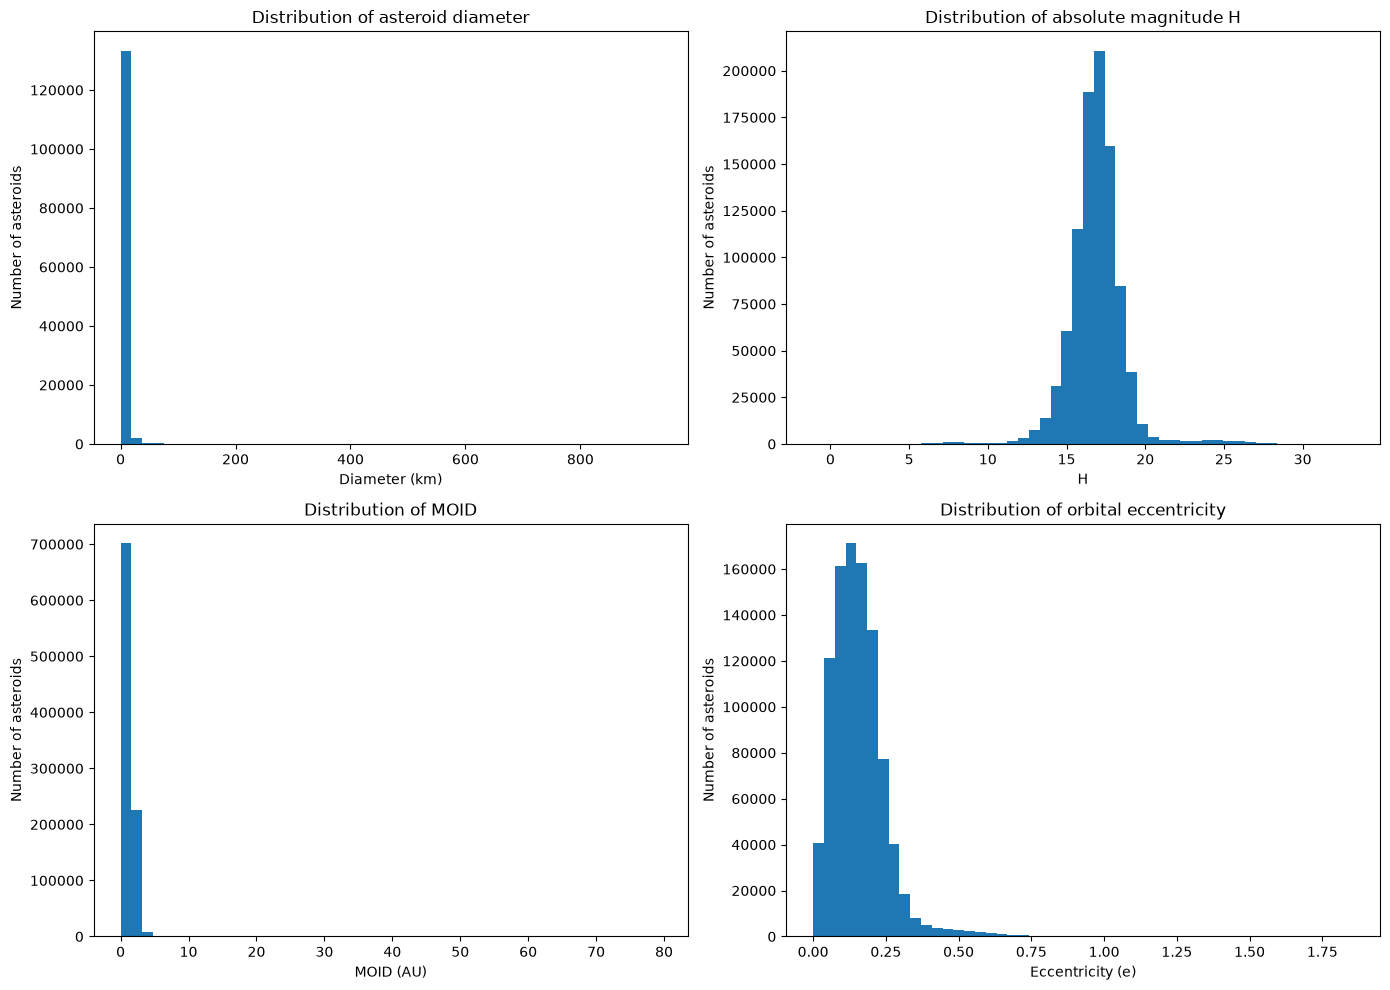

In [9]:
# Подготовим данные для анализа
diameter_data = df["diameter"].dropna()
H_data = df["H"].dropna()
moid_data = df["moid"].dropna()
e_data = df["e"].dropna()

# Создаём область с четырьмя графиками
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Распределение диаметров
axes[0, 0].hist(diameter_data, bins=50)
axes[0, 0].set_title("Distribution of asteroid diameter")
axes[0, 0].set_xlabel("Diameter (km)")
axes[0, 0].set_ylabel("Number of asteroids")

# 2. Абсолютная звёздная величина
axes[0, 1].hist(H_data, bins=50)
axes[0, 1].set_title("Distribution of absolute magnitude H")
axes[0, 1].set_xlabel("H")
axes[0, 1].set_ylabel("Number of asteroids")

# 3. Минимальное расстояние пересечения орбит
axes[1, 0].hist(moid_data, bins=50)
axes[1, 0].set_title("Distribution of MOID")
axes[1, 0].set_xlabel("MOID (AU)")
axes[1, 0].set_ylabel("Number of asteroids")

# 4. Эксцентриситет орбиты
axes[1, 1].hist(e_data, bins=50)
axes[1, 1].set_title("Distribution of orbital eccentricity")
axes[1, 1].set_xlabel("Eccentricity (e)")
axes[1, 1].set_ylabel("Number of asteroids")

plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_23732\926637135.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(diameter_data, vert=False)


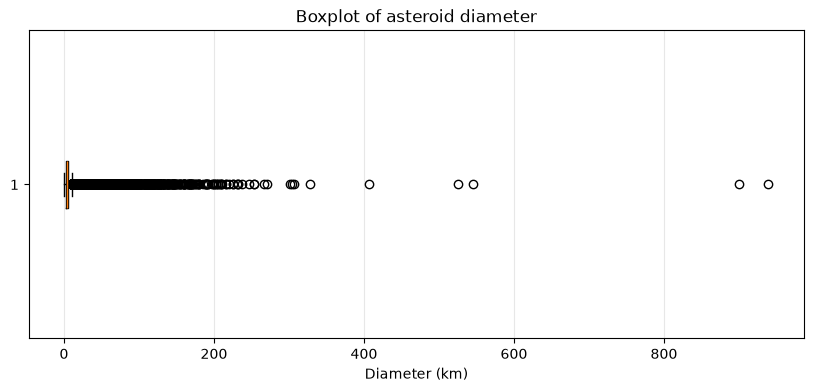

In [10]:
plt.figure(figsize=(10, 4))

plt.boxplot(diameter_data, vert=False)

plt.title("Boxplot of asteroid diameter")
plt.xlabel("Diameter (km)")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [11]:
distribution_summary = df[
    ["diameter", "H", "moid", "e"]
].describe().T

distribution_summary[
    ["count", "mean", "50%", "std", "min", "max"]
]

,count,mean,50%,std,min,max
diameter,136209.0,5.506429,3.972000,9.425164,2.500000e-03,939.400000
H,952261.0,16.906411,16.900000,1.790405,-1.100000e+00,33.200000
moid,938603.0,1.415162,1.240850,2.156731,4.544120e-07,79.476600
e,958524.0,0.156116,0.145002,0.092643,0.000000e+00,1.855356


### Выводы по распределениям

**1. Диаметр астероидов (`diameter`).** Распределение имеет выраженную правостороннюю асимметрию: большинство известных значений диаметра сосредоточено в нижней части диапазона, а небольшое количество астероидов имеет очень большие размеры. Максимальный диаметр в выборке составляет 939,4 км. Это указывает на наличие потенциальных выбросов, которые необходимо исследовать отдельно.

**2. Абсолютная звёздная величина (`H`).** Основная масса значений сосредоточена примерно в диапазоне от 15 до 19. Распределение имеет центральный пик и более редкие значения по краям. Этот признак стоит сохранить для дальнейшего исследования.

**3. Минимальное расстояние между орбитами (`moid`).** Большинство значений находится в нижней части диапазона, однако присутствуют и значительно большие значения. Максимум составляет около 79,48 астрономической единицы. Из-за длинного правого хвоста среднее значение может отличаться от медианы.

**4. Эксцентриситет орбиты (`e`).** Большинство значений сосредоточено примерно между 0,05 и 0,30. Распределение имеет правостороннюю асимметрию. Максимальное значение равно примерно 1,855, поэтому крайние значения следует дополнительно проверить на корректность и особенности исходных орбитальных данных.

**Общий вывод:** распределения нескольких числовых признаков асимметричны. Для дальнейшего анализа необходимо учитывать потенциальные выбросы, проверять корректность экстремальных значений и не удалять наблюдения без обоснованного критерия.


In [12]:
# Проверяем потенциальные выбросы по правилу IQR

features_to_check = ["diameter", "H", "moid", "e"]

outlier_results = []

for feature in features_to_check:
    values = df[feature].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outliers.sum()),
        "outlier_percent": outliers.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary.round(4)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,diameter,2.7800,5.7650,2.9850,-1.6975,10.2425,9613,7.0575
1,H,16.1000,17.7140,1.6140,13.6790,20.1350,44542,4.6775
2,moid,0.9797,1.5934,0.6137,0.0592,2.5139,24551,2.6157
3,e,0.0922,0.2007,0.1085,-0.0705,0.3633,24800,2.5873


### Анализ потенциальных выбросов

Для поиска потенциальных выбросов использовался межквартильный размах (IQR). Значения ниже границы Q1 − 1,5 × IQR или выше границы Q3 + 1,5 × IQR отмечались как потенциальные выбросы.

Наибольшая доля потенциальных выбросов обнаружена у признака `diameter` — около 7,06%. Для `H` эта доля составляет около 4,68%, для `moid` — 2,62%, а для `e` — 2,59%.

Полученные результаты показывают, что распределения признаков неоднородны и содержат крайние значения. Однако экстремальные значения могут отражать реальные свойства астероидов, поэтому автоматически удалять их нельзя. Перед предобработкой необходимо учитывать физический смысл признаков и проверять корректность значений.


In [13]:
# Оставляем только строки с известным значением pha
pha_data = df[df["pha"].isin(["Y", "N"])].copy()

print("Количество объектов с известным pha:", len(pha_data))
print("\nРаспределение классов:")
print(pha_data["pha"].value_counts())

print("\nДоля каждого класса, %:")
print(
    (pha_data["pha"].value_counts(normalize=True) * 100).round(4)
)

Количество объектов с известным pha: 938603

Распределение классов:
pha
N    936537
Y      2066
Name: count, dtype: int64

Доля каждого класса, %:
pha
N    99.7799
Y     0.2201
Name: proportion, dtype: float64


## 3. Сравнение потенциально опасных и остальных астероидов

В этом разделе сравниваются астероиды с `pha = Y` и `pha = N`. Цель — проверить, различаются ли их орбитальные характеристики и какие признаки могут быть полезны для дальнейшей классификации.

Классы сильно несбалансированы: доля объектов `Y` составляет около 0,22%. Поэтому при сравнении необходимо учитывать разницу в размерах групп и не ограничиваться одной метрикой качества.


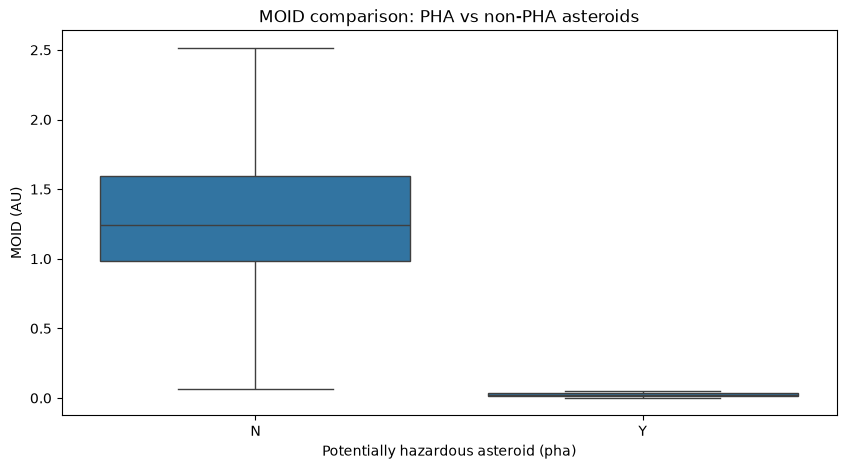

In [14]:
# Сравниваем MOID для двух классов
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=pha_data,
    x="pha",
    y="moid",
    order=["N", "Y"],
    showfliers=False
)

plt.title("MOID comparison: PHA vs non-PHA asteroids")
plt.xlabel("Potentially hazardous asteroid (pha)")
plt.ylabel("MOID (AU)")

plt.show()

In [15]:
moid_comparison = (
    pha_data.groupby("pha")["moid"]
    .describe()
    [["count", "mean", "50%", "std", "min", "max"]]
)

moid_comparison

,count,mean,50%,std,min,max
pha,,,,,,
N,936537.0,1.418232,1.242170,2.158116,4.544120e-07,79.476600
Y,2066.0,0.023670,0.023301,0.014339,2.655650e-05,0.049991


In [16]:
# Подготовка двух независимых групп
moid_N = pha_data.loc[
    pha_data["pha"] == "N", "moid"
].dropna()

moid_Y = pha_data.loc[
    pha_data["pha"] == "Y", "moid"
].dropna()

# Критерий Манна — Уитни
u_statistic, p_value = stats.mannwhitneyu(
    moid_N,
    moid_Y,
    alternative="two-sided"
)

print("Медиана MOID для N:", moid_N.median())
print("Медиана MOID для Y:", moid_Y.median())
print("U-статистика:", u_statistic)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Результат: отвергаем H0 — есть статистические основания считать группы различающимися.")
else:
    print("Результат: недостаточно оснований отвергнуть H0.")

Медиана MOID для N: 1.24217
Медиана MOID для Y: 0.02330055
U-статистика: 1922843574.5
p-value: 0.0
Результат: отвергаем H0 — есть статистические основания считать группы различающимися.
